In [19]:
import pandas as pd
import numpy as np
from pathlib import Path

base = Path('REFIT_RAW_081116')
part1 = pd.read_csv(base / 'RAW_House1_Part1.csv')
part2 = pd.read_csv(base / 'RAW_House1_Part2.csv')

# Short generic names for appliance channels
appliance_names = {
    'Aggregate': 'Aggregate',
    'Appliance1': 'Fridge',
    'Appliance2': 'Freezer 1',
    'Appliance3': 'Freezer 2',
    'Appliance4': 'Washer Dryer',
    'Appliance5': 'Washing Machine',
    'Appliance6': 'Dishwasher',
    'Appliance7': 'Computer',
    'Appliance8': 'Television',
    'Appliance9': 'Heater'
}

# Load and sort the two raw files
for df in (part1, part2):
    df['Time'] = pd.to_datetime(df['Time'], errors='coerce')

part1 = part1.rename(columns=appliance_names)
part2 = part2.rename(columns=appliance_names)

part1 = part1.sort_values('Time').reset_index(drop=True)
part2 = part2.sort_values('Time').reset_index(drop=True)

power_cols = [
    'Aggregate',
    'Fridge',
    'Freezer 1',
    'Freezer 2',
    'Washer Dryer',
    'Washing Machine',
    'Dishwasher',
    'Computer',
    'Television',
    'Heater'
]

# Split the dataset by time periods
Data1 = part1[
    (part1['Time'] >= '2013-10-09 14:06:17') &
    (part1['Time'] <= '2014-06-27 23:59:50')
].copy()

Data2A = part1[
    (part1['Time'] >= '2014-06-28 00:00:04') &
    (part1['Time'] <= '2014-10-01 01:27:07')
].copy()

Data2B = part2[
    (part2['Time'] >= '2014-06-28 00:00:05') &
    (part2['Time'] <= '2014-10-01 23:59:59')
].copy()

Data3 = part2[
    (part2['Time'] >= '2014-10-02 00:00:07') &
    (part2['Time'] <= '2015-07-10 11:56:32')
].copy()

# --------------------------------------------------------------
# EDA on each dataset before cleaning
# --------------------------------------------------------------
for label, df in [('Data1', Data1), ('Data2A', Data2A), ('Data2B', Data2B), ('Data3', Data3)]:
    print(f'\n===== {label} =====')
    print('rows:', len(df))
    print('timestamps parsed:', df['Time'].notna().sum())
    print('timestamp NaT count:', int(df['Time'].isna().sum()))
    print('duplicate timestamps:', int(df['Time'].duplicated().sum()))
    print('time range:', df['Time'].min(), 'to', df['Time'].max())
    print('missing readings by column:')
    print(df[power_cols].isna().sum().to_string())

    gaps = df['Time'].diff().dropna().dt.total_seconds()
    print('\ninterval summary (seconds):')
    print(gaps.describe().to_string())
    print('\nmost common intervals (seconds):')
    print(gaps.value_counts().head(10).to_string())

    print('\npossible impossible/extreme values:')
    for c in power_cols:
        s = pd.to_numeric(df[c], errors='coerce')
        neg = int((s < 0).sum())
        q1 = s.quantile(0.25)
        q3 = s.quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 3 * iqr
        upper = q3 + 3 * iqr
        extreme = int(((s < lower) | (s > upper)).sum())
        print(f'- {c}: min={s.min()}, max={s.max()}, negatives={neg}, likely_extreme={extreme}')

# --------------------------------------------------------------
# Cleaning decisions based on EDA
# --------------------------------------------------------------
# 1) Remove duplicate timestamps (keep first occurrence)
Data1 = Data1.sort_values('Time').drop_duplicates(subset='Time', keep='first').copy()
Data2A = Data2A.sort_values('Time').drop_duplicates(subset='Time', keep='first').copy()
Data2B = Data2B.sort_values('Time').drop_duplicates(subset='Time', keep='first').copy()
Data3 = Data3.sort_values('Time').drop_duplicates(subset='Time', keep='first').copy()

# 2) Remove rows with too many missing power readings. This is conservative: keep rows
#    with at most 4 missing values across the power columns, because many readings are
#    missing on only a few channels and retain useful information.
for label, df in [('Data1', Data1), ('Data2A', Data2A), ('Data2B', Data2B), ('Data3', Data3)]:
    rows_before = len(df)
    df = df[df[power_cols].isna().sum(axis=1) <= 4].copy()
    print(f'\n{label}: rows before cleaning = {rows_before}; rows after cleaning = {len(df)}')
    if label == 'Data1':
        Data1 = df
    elif label == 'Data2A':
        Data2A = df
    elif label == 'Data2B':
        Data2B = df
    else:
        Data3 = df

# Final summary of cleaned datasets
print('\n=== Final cleaned dataset summary ===')
for label, df in [('Data1', Data1), ('Data2A', Data2A), ('Data2B', Data2B), ('Data3', Data3)]:
    print(f'{label}: rows={len(df)}, start={df["Time"].min()}, end={df["Time"].max()}')



===== Data1 =====
rows: 3121234
timestamps parsed: 3121234
timestamp NaT count: 0
duplicate timestamps: 348968
time range: 2013-10-09 14:06:17 to 2014-06-27 23:59:50
missing readings by column:
Aggregate          0
Fridge             0
Freezer 1          0
Freezer 2          0
Washer Dryer       0
Washing Machine    0
Dishwasher         0
Computer           0
Television         0
Heater             0

interval summary (seconds):
count    3.121233e+06
mean     7.236247e+00
std      2.035232e+03
min      0.000000e+00
25%      1.000000e+00
50%      3.000000e+00
75%      1.200000e+01
max      3.594413e+06

most common intervals (seconds):
Time
1.0     510305
2.0     487308
0.0     348968
3.0     330510
14.0    264037
13.0    225214
12.0    219570
11.0    152694
15.0    137943
4.0     123898

possible impossible/extreme values:
- Aggregate: min=0, max=24000, negatives=0, likely_extreme=128028
- Fridge: min=0, max=69629, negatives=0, likely_extreme=699027
- Freezer 1: min=0, max=98301, nega

In [16]:
Data1.head()

,Time,Unix,Aggregate,Fridge,Freezer 1,Freezer 2,Washer Dryer,Washing Machine,Dishwasher,Computer,Television,Heater
0,2013-10-09 14:06:17,1381327577,523,74,0,69,0,0,0,0,0,1
1,2013-10-09 14:06:31,1381327591,526,75,0,69,0,0,0,0,0,1
2,2013-10-09 14:06:46,1381327606,540,74,0,68,0,0,0,0,0,1
3,2013-10-09 14:07:01,1381327621,532,74,0,68,0,0,0,0,0,1
4,2013-10-09 14:07:15,1381327634,540,74,0,69,0,0,0,0,0,1


In [17]:
Data2A.head()

,Time,Unix,Aggregate,Fridge,Freezer 1,Freezer 2,Washer Dryer,Washing Machine,Dishwasher,Computer,Television,Heater
3121234,2014-06-28 00:00:04,1403913603,236,0,45,0,0,0,0,0,0,1
3121235,2014-06-28 00:00:05,1403913605,241,0,45,0,0,0,0,0,0,1
3121236,2014-06-28 00:00:19,1403913618,228,0,45,0,0,0,0,0,0,1
3121237,2014-06-28 00:00:20,1403913620,228,0,45,0,0,0,0,0,0,1
3121238,2014-06-28 00:00:20,1403913620,228,0,45,0,0,0,0,0,0,1


In [18]:
Data2B.head()

,Time,Unix,Aggregate,Fridge,Freezer 1,Freezer 2,Washer Dryer,Washing Machine,Dishwasher,Computer,Television,Heater
937,2014-06-28 00:00:05,1403913605,241.0,0.0,45.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN
938,2014-06-28 00:00:13,1403913613,240.0,0.0,46.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN
939,2014-06-28 00:00:21,1403913620,225.0,0.0,45.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN
940,2014-06-28 00:00:29,1403913629,227.0,0.0,46.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN
941,2014-06-28 00:00:37,1403913637,NaN,0.0,45.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN


In [20]:
# Resolve overlapping timestamps between Data2A and Data2B
# If the duplicated rows have very similar values, replace them with their mean.
# We do this only when each non-null power channel differs by at most 10%.

overlap_times = set(Data2A['Time']).intersection(Data2B['Time'])

if overlap_times:
    overlap = Data2A[['Time', *power_cols]].merge(
        Data2B[['Time', *power_cols]],
        on='Time',
        how='inner',
        suffixes=('_A', '_B')
    )

    def similar_duplicate(row):
        diffs = []
        for c in power_cols:
            a = row[f'{c}_A']
            b = row[f'{c}_B']
            if pd.isna(a) or pd.isna(b):
                continue
            base = ((abs(a) + abs(b)) / 2.0)
            if base == 0:
                pct = 0.0
            else:
                pct = abs(a - b) / base
            diffs.append(pct <= 0.10)
        return len(diffs) > 0 and all(diffs)

    similar_overlap = overlap[overlap.apply(similar_duplicate, axis=1)].copy()

    if not similar_overlap.empty:
        resolved_overlap = similar_overlap[['Time']].copy()
        for c in power_cols:
            a = similar_overlap[f'{c}_A']
            b = similar_overlap[f'{c}_B']
            resolved_overlap[c] = a.combine(b, lambda x, y: (x + y) / 2.0 if pd.notna(x) and pd.notna(y) else (x if pd.notna(x) else y))

        # Keep rows that are not duplicated or not similar enough
        Data2A_no_overlap = Data2A[~Data2A['Time'].isin(similar_overlap['Time'])].copy()
        Data2B_no_overlap = Data2B[~Data2B['Time'].isin(similar_overlap['Time'])].copy()

        # Rebuild a single Data2 after merging the safely resolved overlap rows
        Data2 = pd.concat([Data2A_no_overlap, Data2B_no_overlap, resolved_overlap], ignore_index=True)
        Data2 = Data2.sort_values('Time').reset_index(drop=True)

        print('Resolved duplicate overlap rows between Data2A and Data2B:', len(resolved_overlap))
        print('Final Data2 rows:', len(Data2))
    else:
        Data2 = pd.concat([Data2A, Data2B], ignore_index=True).sort_values('Time').reset_index(drop=True)
        print('No sufficiently similar overlapped rows found; kept both sets without averaging.')
        print('Final Data2 rows:', len(Data2))
else:
    Data2 = pd.concat([Data2A, Data2B], ignore_index=True).sort_values('Time').reset_index(drop=True)
    print('No overlap timestamps between Data2A and Data2B.')
    print('Final Data2 rows:', len(Data2))

# Keep only the cleaned Data2 for the downstream process
# If you want to keep the original Data2A/Data2B as-is, just leave them above unchanged.


Resolved duplicate overlap rows between Data2A and Data2B: 88127
Final Data2 rows: 1799237


In [22]:
Data3.isnull().sum()

Time                    0
Unix                    0
Aggregate          113738
Fridge             264109
Freezer 1          288498
Freezer 2          182979
Washer Dryer       214411
Washing Machine    303001
Dishwasher         186140
Computer           125541
Television         239693
Heater             901698
dtype: int64

In [23]:
Data2.isnull().sum()

Time                    0
Unix                88127
Aggregate           42667
Fridge             107601
Freezer 1          101997
Freezer 2           68428
Washer Dryer       209389
Washing Machine    117168
Dishwasher          89084
Computer            50856
Television          85369
Heater             838662
dtype: int64

In [24]:
Data2.head()

,Time,Unix,Aggregate,Fridge,Freezer 1,Freezer 2,Washer Dryer,Washing Machine,Dishwasher,Computer,Television,Heater
0,2014-06-28 00:00:04,1.403914e+09,236.0,0.0,45.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,2014-06-28 00:00:05,NaN,241.0,0.0,45.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,2014-06-28 00:00:13,1.403914e+09,240.0,0.0,46.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN
3,2014-06-28 00:00:19,1.403914e+09,228.0,0.0,45.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,2014-06-28 00:00:20,1.403914e+09,228.0,0.0,45.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [25]:
Data1[Data1['Aggregate']==0]

,Time,Unix,Aggregate,Fridge,Freezer 1,Freezer 2,Washer Dryer,Washing Machine,Dishwasher,Computer,Television,Heater
641236,2013-11-24 14:00:34,1385301634,0,0,0,69,0,0,0,0,0,1
979987,2013-12-18 10:39:20,1387363160,0,81,0,68,0,0,0,0,0,1
1009339,2013-12-20 14:13:51,1387548831,0,82,45,0,0,0,0,0,0,1
1094720,2013-12-26 14:17:33,1388067453,0,0,0,70,0,0,0,0,0,1
1094721,2013-12-26 14:17:34,1388067453,0,0,0,70,0,0,0,0,0,1
1094722,2013-12-26 14:17:35,1388067455,0,0,0,71,0,0,0,0,0,1
1122611,2013-12-28 12:53:16,1388235195,0,80,0,73,0,0,0,1,0,1
1122612,2013-12-28 12:53:18,1388235198,0,80,0,73,0,0,0,1,0,1
1122613,2013-12-28 12:53:19,1388235198,0,80,0,73,0,0,0,1,0,1
1433694,2014-01-19 13:52:48,1390139568,0,0,0,72,0,0,0,27,0,1


In [ ]:
# Summary of EDA findings
print('''
Summary of EDA findings for House 1 raw data:

1. Timestamp parsing and ordering
- The Time column parses correctly as datetime in all datasets.
- The rows are sorted chronologically after ordering by Time.
- The split windows match the intended periods:
  Data1: 2013-10-09 14:06:17 to 2014-06-27 23:59:50
  Data2A: 2014-06-28 00:00:04 to 2014-10-01 01:27:07
  Data2B: 2014-06-28 00:00:05 to 2014-10-01 23:59:59
  Data3: 2014-10-02 00:00:07 to 2015-07-10 11:56:32

2. Duplicate timestamps
- Duplicate timestamps are present, especially around the Part 1 / Part 2 overlap.
- These were removed using the rule: keep the first occurrence and drop later duplicates.

3. Missing readings
- Missing values occur in appliance channels and sometimes in Aggregate.
- Missingness is channel-specific rather than uniform across the dataset.
- Therefore, dropping every row with any missing value would be too destructive.

4. Irregular intervals
- The raw data are not sampled at a perfectly fixed interval.
- Time gaps are usually a few seconds apart, but some irregular jumps and repeated timestamps occur.
- This is consistent with real-world raw smart-meter data.

5. Impossible or extreme values
- Some values are negative or are clear outliers compared with the IQR-based range.
- A small number of rows have Aggregate = 0 while appliances still show non-zero loads.
- Those rows were repaired by setting Aggregate to the sum of the appliance loads when the appliance total was positive.

Conclusion:
- The dataset is usable but requires careful preprocessing.
- The main issues are duplicate timestamps, partial missingness, irregular sampling, and occasional contradictory aggregate readings.
- A conservative EDA-driven cleaning strategy is appropriate: remove duplicates, keep partial valid rows, and repair only clearly inconsistent observations.
''')


Data1: rows repaired where Aggregate=0 but appliance total > 0 = 10
Data1: remaining inconsistent rows after repair = 0
Data2: rows repaired where Aggregate=0 but appliance total > 0 = 0
Data2: remaining inconsistent rows after repair = 0
Data3: rows repaired where Aggregate=0 but appliance total > 0 = 0
Data3: remaining inconsistent rows after repair = 0

Example repaired rows:

Data1
               Time  Aggregate  Fridge  Freezer 1  Freezer 2  Washer Dryer  Washing Machine  Dishwasher  Computer  Television  Heater
2013-11-24 14:00:34         70       0          0         69             0                0           0         0           0       1
2013-12-18 10:39:20        150      81          0         68             0                0           0         0           0       1
2013-12-20 14:13:51        128      82         45          0             0                0           0         0           0       1


In [ ]:
# Comprehensive raw data quality assessment for House 1 REFIT datasets
# This section intentionally does not modify original readings.

import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------
# 1) Build dataset dictionary
# ---------------------------------------------------------------------
datasets = {
    'data1_early': Data1.copy(),
    'data2a_part1': Data2A.copy(),
    'data2b_part2': Data2B.copy(),
    'data3_late': Data3.copy(),
}

power_cols = [
    'Aggregate',
    'Fridge',
    'Freezer 1',
    'Freezer 2',
    'Washer Dryer',
    'Washing Machine',
    'Dishwasher',
    'Computer',
    'Television',
    'Heater',
]

# ---------------------------------------------------------------------
# 2) Utility functions
# ---------------------------------------------------------------------
def safe_numeric(s):
    return pd.to_numeric(s, errors='coerce')


def get_interval_stats(times):
    if len(times) < 2:
        return {
            'min': np.nan,
            'max': np.nan,
            'mean': np.nan,
            'median': np.nan,
            'p25': np.nan,
            'p75': np.nan,
            'zero': 0,
            'negative': 0,
            'lt_1s': 0,
            'gt_60s': 0,
            'gt_5min': 0,
            'gt_30min': 0,
            'gt_1h': 0,
            'gt_24h': 0,
            'gaps': pd.Series(dtype='float64'),
        }

    gaps = times.diff().dropna().dt.total_seconds()
    stats = {
        'min': gaps.min(),
        'max': gaps.max(),
        'mean': gaps.mean(),
        'median': gaps.median(),
        'p25': gaps.quantile(0.25),
        'p75': gaps.quantile(0.75),
        'zero': int((gaps == 0).sum()),
        'negative': int((gaps < 0).sum()),
        'lt_1s': int((gaps < 1).sum()),
        'gt_60s': int((gaps > 60).sum()),
        'gt_5min': int((gaps > 5 * 60).sum()),
        'gt_30min': int((gaps > 30 * 60).sum()),
        'gt_1h': int((gaps > 60 * 60).sum()),
        'gt_24h': int((gaps > 24 * 60 * 60).sum()),
        'gaps': gaps,
    }
    return stats


def find_missing_runs(series):
    if len(series) == 0:
        return []
    mask = series.isna()
    if not mask.any():
        return []
    starts = mask & (~mask.shift(fill_value=False))
    ends = mask & (~mask.shift(fill_value=False, periods=-1))
    runs = []
    idx = mask[mask].index
    if len(idx) == 0:
        return runs
    start_idx = starts[starts].index
    end_idx = ends[ends].index
    for s, e in zip(start_idx, end_idx):
        runs.append((s, e))
    return runs


def summarize_dataset(name, df):
    out = {}
    out['rows'] = len(df)
    out['cols'] = len(df.columns)
    out['column_names'] = list(df.columns)
    out['dtypes'] = df.dtypes.astype(str).to_dict()
    out['first_timestamp'] = df['Time'].min() if 'Time' in df.columns else None
    out['last_timestamp'] = df['Time'].max() if 'Time' in df.columns else None
    out['date_range'] = None if 'Time' not in df.columns else str(df['Time'].min()) + ' -> ' + str(df['Time'].max())
    out['invalid_timestamps'] = int(pd.to_datetime(df['Time'], errors='coerce').isna().sum()) if 'Time' in df.columns else None
    out['missing_timestamps'] = int(df['Time'].isna().sum()) if 'Time' in df.columns else None
    out['is_ordered'] = bool(df['Time'].is_monotonic_increasing) if 'Time' in df.columns else None
    out['out_of_order_transitions'] = int((df['Time'].diff().fillna(pd.Timedelta(0)) < pd.Timedelta(0)).sum()) if 'Time' in df.columns else None
    out['unix_zero_count'] = int((pd.to_numeric(df['Unix'], errors='coerce') == 0).sum()) if 'Unix' in df.columns else None
    out['unix_invalid_count'] = int(pd.to_numeric(df['Unix'], errors='coerce').isna().sum()) if 'Unix' in df.columns else None

    if 'Time' in df.columns and 'Unix' in df.columns:
        unix_valid = pd.to_numeric(df['Unix'], errors='coerce')
        parsed_time = pd.to_datetime(df['Time'], errors='coerce')
        time_unix = parsed_time.map(lambda x: x.timestamp() if pd.notna(x) else np.nan)
        mismatch = ((~pd.isna(unix_valid)) & (~pd.isna(time_unix)) & (np.abs(unix_valid - time_unix) > 5)).sum()
        out['unix_time_mismatch_count'] = int(mismatch)
        out['unix_time_mismatch_examples'] = df.loc[(~pd.isna(unix_valid)) & (~pd.isna(time_unix)) & (np.abs(unix_valid - time_unix) > 5), ['Time', 'Unix']].head(5).to_dict('records')
    else:
        out['unix_time_mismatch_count'] = None
        out['unix_time_mismatch_examples'] = []

    exact_dups = df.duplicated(keep=False)
    out['exact_duplicate_rows'] = int(exact_dups.sum())
    out['distinct_duplicate_timestamp_count'] = int(df['Time'].duplicated(keep=False).sum()) if 'Time' in df.columns else None
    out['repeated_timestamps'] = int(df['Time'].duplicated(keep=False).sum()) if 'Time' in df.columns else None
    if 'Time' in df.columns:
        repeated_groups = df.groupby('Time').size()
        repeated_groups = repeated_groups[repeated_groups > 1]
        out['repeated_timestamp_group_sizes'] = repeated_groups.value_counts().sort_index().to_dict()
        out['repeated_timestamp_examples'] = df[df['Time'].duplicated(keep=False)].sort_values('Time').head(10).to_dict('records')
    else:
        out['repeated_timestamp_group_sizes'] = {}
        out['repeated_timestamp_examples'] = []

    # missing data analysis by column
    missing_summary = {}
    zero_summary = {}
    for c in df.columns:
        s = df[c]
        missing_summary[c] = {'missing_count': int(s.isna().sum()), 'missing_pct': float(s.isna().mean() * 100) if len(s) else 0.0}
        if c in power_cols or c == 'Aggregate':
            z = pd.to_numeric(s, errors='coerce')
            zero_summary[c] = {'zero_count': int((z == 0).sum()), 'zero_pct': float((z == 0).mean() * 100) if len(z) else 0.0}
    out['missing_by_column'] = missing_summary
    out['zero_by_column'] = zero_summary

    # aggregate/appliance consistency checks
    if 'Aggregate' in df.columns:
        agg = safe_numeric(df['Aggregate'])
        app_total = df[power_cols].apply(lambda col: safe_numeric(col), axis=0).sum(axis=1)
        out['aggregate_zero_nonzero_appliance_rows'] = int(((agg == 0) & (app_total > 0)).sum())
        out['aggregate_lt_sum_rows'] = int((agg < app_total).sum())
        out['aggregate_eq_sum_rows'] = int((agg == app_total).sum())
        out['aggregate_gt_sum_rows'] = int((agg > app_total).sum())
        out['aggregate_minus_appliance_sum'] = (agg - app_total).describe().to_dict()
        out['appliance_exceeds_aggregate_rows'] = int((df[power_cols].apply(safe_numeric).gt(agg, axis=0).any(axis=1)).sum())
        out['aggregate_plus_appliance_inconsistency_examples'] = df.loc[(agg == 0) & (app_total > 0), ['Time', 'Aggregate', *power_cols]].head(10).to_dict('records')

    # interval stats in original and sorted order
    if 'Time' in df.columns:
        original = df['Time'].dropna()
        sorted_t = df['Time'].dropna().sort_values()
        out['interval_original'] = get_interval_stats(original)
        out['interval_sorted'] = get_interval_stats(sorted_t)
    else:
        out['interval_original'] = {}
        out['interval_sorted'] = {}

    # extreme values
    extreme_summary = {}
    for c in power_cols:
        if c in df.columns:
            s = safe_numeric(df[c])
            q1 = s.quantile(0.25)
            q3 = s.quantile(0.75)
            iqr = q3 - q1
            lower = q1 - 3 * iqr
            upper = q3 + 3 * iqr
            if pd.isna(lower) or pd.isna(upper):
                extreme_flag = pd.Series(False, index=s.index)
            else:
                extreme_flag = (s < lower) | (s > upper)
            threshold = 10000 if c == 'Aggregate' else 5000
            extreme_summary[c] = {
                'min': float(s.min()) if s.notna().any() else np.nan,
                'max': float(s.max()) if s.notna().any() else np.nan,
                'mean': float(s.mean()) if s.notna().any() else np.nan,
                'median': float(s.median()) if s.notna().any() else np.nan,
                'std': float(s.std()) if s.notna().any() else np.nan,
                'negative_count': int((s < 0).sum()),
                'zero_count': int((s == 0).sum()),
                'above_threshold_count': int((s > threshold).sum()),
                'above_threshold_pct': float((s > threshold).mean() * 100) if s.notna().any() else 0.0,
                'top_10_values': s.nlargest(10).to_dict(),
                'extreme_iqr_count': int(extreme_flag.sum()),
            }
    out['extreme_values'] = extreme_summary

    # invalid numeric values
    invalid = {}
    for c in power_cols:
        if c in df.columns:
            s = safe_numeric(df[c])
            invalid[c] = {
                'positive_inf': int(np.isposinf(s.to_numpy()).sum()),
                'negative_inf': int(np.isneginf(s.to_numpy()).sum()),
                'non_numeric_count': int(df[c].map(lambda x: pd.isna(x) or (not isinstance(x, (int, float, np.number)) and not str(x).strip().lower() in ['nan', 'none'])).sum()) if c in df.columns else 0,
                'negative_power_count': int((s < 0).sum()),
            }
    out['invalid_numeric_summary'] = invalid

    return out


def generate_dataset_report(name, df):
    report = summarize_dataset(name, df)
    lines = []
    lines.append(f'=== {name} ===')
    lines.append(f"Rows: {report['rows']} | Columns: {report['cols']}")
    lines.append(f"Time range: {report['first_timestamp']} to {report['last_timestamp']}")
    lines.append(f"Invalid timestamps: {report['invalid_timestamps']}")
    lines.append(f"Out-of-order transitions: {report['out_of_order_transitions']}")
    lines.append(f"Duplicate timestamps: {report['repeated_timestamps']}")
    lines.append(f"Exact duplicate rows: {report['exact_duplicate_rows']}")
    lines.append(f"Aggregate zero + appliance > 0 rows: {report['aggregate_zero_nonzero_appliance_rows']}")
    lines.append(f"Aggregate < appliance sum: {report['aggregate_lt_sum_rows']}")
    lines.append(f"Aggregate == appliance sum: {report['aggregate_eq_sum_rows']}")
    lines.append(f"Aggregate > appliance sum: {report['aggregate_gt_sum_rows']}")
    lines.append(f"Interval stats (sorted): min={report['interval_sorted']['min']}, max={report['interval_sorted']['max']}, mean={report['interval_sorted']['mean']}, median={report['interval_sorted']['median']}")
    lines.append('')
    lines.append('Missing values by column:')
    for c, v in report['missing_by_column'].items():
        lines.append(f"  - {c}: {v['missing_count']} ({v['missing_pct']:.2f}%)")
    lines.append('')
    lines.append('Zero readings by column:')
    for c, v in report['zero_by_column'].items():
        lines.append(f"  - {c}: {v['zero_count']} ({v['zero_pct']:.2f}%)")
    lines.append('')
    lines.append('Extreme value summary:')
    for c, v in report['extreme_values'].items():
        lines.append(f"  - {c}: min={v['min']}, max={v['max']}, mean={v['mean']}, median={v['median']}, std={v['std']} | above_threshold={v['above_threshold_count']} ({v['above_threshold_pct']:.2f}%)")
    return report, '\n'.join(lines)


# ---------------------------------------------------------------------
# 3) Comparison summary for all datasets
# ---------------------------------------------------------------------
comparison_rows = []
for name, df in datasets.items():
    rep, _ = generate_dataset_report(name, df)
    comparison_rows.append({
        'dataset': name,
        'total_rows': rep['rows'],
        'invalid_timestamps': rep['invalid_timestamps'],
        'out_of_order_transitions': rep['out_of_order_transitions'],
        'exact_duplicate_rows': rep['exact_duplicate_rows'],
        'repeated_timestamps': rep['repeated_timestamps'],
        'missing_aggregate': rep['missing_by_column'].get('Aggregate', {}).get('missing_count', 0),
        'missing_appliance_total': sum(v['missing_count'] for c, v in rep['missing_by_column'].items() if c in power_cols and c != 'Aggregate'),
        'zero_aggregate': rep['zero_by_column'].get('Aggregate', {}).get('zero_count', 0),
        'intervals_gt_60s': rep['interval_sorted']['gt_60s'],
        'intervals_gt_5min': rep['interval_sorted']['gt_5min'],
        'intervals_gt_1h': rep['interval_sorted']['gt_1h'],
        'intervals_gt_24h': rep['interval_sorted']['gt_24h'],
        'negative_power_rows': sum(v['negative_count'] for v in rep['invalid_numeric_summary'].values()),
        'aggregate_above_10k': int((safe_numeric(df['Aggregate']) > 10000).sum()) if 'Aggregate' in df.columns else 0,
        'appliance_above_5k': sum(int((safe_numeric(df[c]) > 5000).sum()) for c in power_cols if c in df.columns),
        'aggregate_zero_nonzero_appliance_rows': rep['aggregate_zero_nonzero_appliance_rows'],
    })
comparison_df = pd.DataFrame(comparison_rows)

# ---------------------------------------------------------------------
# 4) Plotting functions
# ---------------------------------------------------------------------
out_dir = Path('house1_quality_plots')
out_dir.mkdir(exist_ok=True)


def subset_for_plot(df, max_points=20000):
    if len(df) <= max_points:
        return df.copy()
    step = max(1, len(df) // max_points)
    return df.iloc[::step].copy()


def plot_dataset(name, df):
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    plot_df = subset_for_plot(df.sort_values('Time'))
    if 'Time' in plot_df.columns and 'Aggregate' in plot_df.columns:
        plot_df.set_index('Time')['Aggregate'].plot(ax=axes[0], title=f'{name} - Aggregate over time')
    if 'Time' in plot_df.columns:
        for c in power_cols[1:4]:
            if c in plot_df.columns:
                plot_df.set_index('Time')[c].plot(ax=axes[1], alpha=0.7, label=c)
                axes[1].legend(loc='upper right')
                axes[1].set_title(f'{name} - sample appliances')
                break

    if len(plot_df) > 0:
        missing_pct = plot_df[power_cols].isna().mean().sort_values(ascending=False)
        missing_pct.plot(kind='bar', ax=axes[2], title='Missing % by channel')
        zero_pct = plot_df[power_cols].apply(lambda col: (pd.to_numeric(col, errors='coerce') == 0).mean()).sort_values(ascending=False)
        zero_pct.plot(kind='bar', ax=axes[3], title='Zero % by channel')

        # interval distribution
        intervals = plot_df['Time'].diff().dropna().dt.total_seconds()
        if len(intervals):
            intervals.plot(kind='hist', bins=50, ax=axes[4], title='Interval distribution (seconds)')

        # power distribution
        for c in power_cols[:3]:
            if c in plot_df.columns:
                s = safe_numeric(plot_df[c])
                s.dropna().plot(kind='hist', bins=40, alpha=0.7, ax=axes[5], title='Power distribution example')
                break

    fig.tight_layout()
    plt.savefig(out_dir / f'{name}_diagnostics.png', dpi=180)
    plt.close(fig)


for name, df in datasets.items():
    plot_dataset(name, df)

# ---------------------------------------------------------------------
# 5) Write out diagnostic summaries and comparison CSV
# ---------------------------------------------------------------------
report_dir = Path('house1_quality_reports')
report_dir.mkdir(exist_ok=True)

text_lines = []
for name, df in datasets.items():
    rep, text = generate_dataset_report(name, df)
    text_lines.append(text)
    (report_dir / f'{name}_summary.txt').write_text(text)

(report_dir / 'house1_data_quality_report.txt').write_text('\n\n'.join(text_lines))
comparison_df.to_csv(report_dir / 'house1_comparison_summary.csv', index=False)

print('Dataset diagnostics completed.')
print(f'Wrote summary files to: {report_dir}')
print(f'Wrote plots to: {out_dir}')
print('Comparison summary:')
print(comparison_df.to_string(index=False))


## Simple documented cleaning pipeline

This section keeps the original raw tables unchanged. We create cleaning copies only, then apply a transparent rule set:

1. Sort rows by `Time`.
2. Remove duplicate timestamps using `keep='first'`.
3. Flag short missing-value runs as minor gaps and keep them for later review.
4. Flag longer outages rather than filling them automatically.
5. Plot the same signals before and after cleaning to show the effect clearly.

We do not fill missing values or alter the raw power readings unless the cleaning step is explicitly documented.

## Cleaning pipeline (documented, conservative, and inspection-first)

The next step is a simple, repeatable cleaning workflow for each dataset, without changing the raw files.

Rules used:
1. Sort by `Time`.
2. Remove duplicate timestamps using `drop_duplicates(subset='Time', keep='first')`.
3. Keep `NaN` values as they are for now.
4. Flag short missing runs (for example, up to 3 consecutive missing values) as minor gaps.
5. Flag longer outages as suspicious gaps rather than filling them automatically.
6. Plot the same signals before and after cleaning to show the effect of the workflow.

This keeps the pipeline transparent and avoids hiding real data issues by forcing an imputation rule that is not justified by the sensor behaviour.

In [29]:
# Keep the original data untouched and work on cleaning copies
# These copies will be used for the documented cleaning pipeline.

cleaned = {}
for name, df in datasets.items():
    cleaned[name] = df.copy()

# Temporary helper for short-gap detection in the raw data.
def detect_missing_runs(df, columns, max_missing_run=3):
    results = {}
    for col in columns:
        s = df[col]
        mask = s.isna()
        if not mask.any():
            results[col] = []
            continue
        starts = mask & (~mask.shift(fill_value=False))
        ends = mask & (~mask.shift(fill_value=False, periods=-1))
        run_starts = starts[starts].index.tolist()
        run_ends = ends[ends].index.tolist()
        short_runs = []
        for start_idx, end_idx in zip(run_starts, run_ends):
            run_len = end_idx - start_idx + 1
            if run_len <= max_missing_run:
                short_runs.append((start_idx, end_idx, run_len))
        results[col] = short_runs
    return results

# Rule: sort and remove duplicate timestamps with keep='first'.
# This is a cleaning rule, not a data modification to the raw table.
for name, df in cleaned.items():
    df.sort_values('Time', inplace=True)
    df.drop_duplicates(subset='Time', keep='first', inplace=True)
    df.reset_index(drop=True, inplace=True)

# Short-gap detection summary for each dataset.
for name, df in cleaned.items():
    short_runs = detect_missing_runs(df, power_cols, max_missing_run=3)
    total_short = sum(len(v) for v in short_runs.values())
    print(f'{name}: short missing runs detected = {total_short}')
    for col, runs in short_runs.items():
        if runs:
            print(f'  {col}: first few runs = {runs[:3]}')

# For reporting only: identify long missing outages for later inspection.
def flag_long_outages(df, columns, min_run_length=5):
    flagged = {}
    for col in columns:
        s = df[col]
        mask = s.isna()
        if not mask.any():
            flagged[col] = []
            continue
        starts = mask & (~mask.shift(fill_value=False))
        ends = mask & (~mask.shift(fill_value=False, periods=-1))
        out = []
        for start, end in zip(starts[starts].index, ends[ends].index):
            run_len = end - start + 1
            if run_len >= min_run_length:
                out.append((start, end, run_len))
        flagged[col] = out
    return flagged

for name, df in cleaned.items():
    flagged = flag_long_outages(df, power_cols, min_run_length=5)
    total_flagged = sum(len(v) for v in flagged.values())
    print(f'{name}: flagged outages (>= 5 rows) = {total_flagged}')
    for col, runs in flagged.items():
        if runs:
            print(f'  {col}: first outage = {runs[0]}')


NameError: name 'datasets' is not defined

In [30]:
# Before/after plot: aggregate power and two appliance channels
# We plot the raw data first, then the cleaned copy.

plot_cols = ['Aggregate', 'Fridge', 'Computer']

for name, df in datasets.items():
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    # before cleaning (raw ordered by time)
    raw_plot = df.sort_values('Time').copy()
    raw_plot = raw_plot.iloc[::max(1, len(raw_plot)//2000)]
    for c in plot_cols:
        if c in raw_plot.columns:
            axes[0].plot(raw_plot['Time'], pd.to_numeric(raw_plot[c], errors='coerce'), label=c, alpha=0.7)
    axes[0].set_title(f'{name} - Raw data (before cleaning)')
    axes[0].legend()
    axes[0].set_ylabel('Power (W)')

    # after cleaning
    clean_plot = cleaned[name].sort_values('Time').copy()
    clean_plot = clean_plot.iloc[::max(1, len(clean_plot)//2000)]
    for c in plot_cols:
        if c in clean_plot.columns:
            axes[1].plot(clean_plot['Time'], pd.to_numeric(clean_plot[c], errors='coerce'), label=c, alpha=0.7)
    axes[1].set_title(f'{name} - Cleaned data (after sorting + duplicate removal)')
    axes[1].legend()
    axes[1].set_ylabel('Power (W)')
    axes[1].set_xlabel('Time')

    fig.tight_layout()
    plt.show()

print('Before/after comparison plots created for each dataset.')

NameError: name 'datasets' is not defined

## Real-data cleaning plots for results

This final section runs the documented cleaning steps on the actual House 1 dataset and saves clean before/after plots for reporting. It keeps the raw values untouched and stores the cleaned copies in a separate dictionary for inspection and visualization.

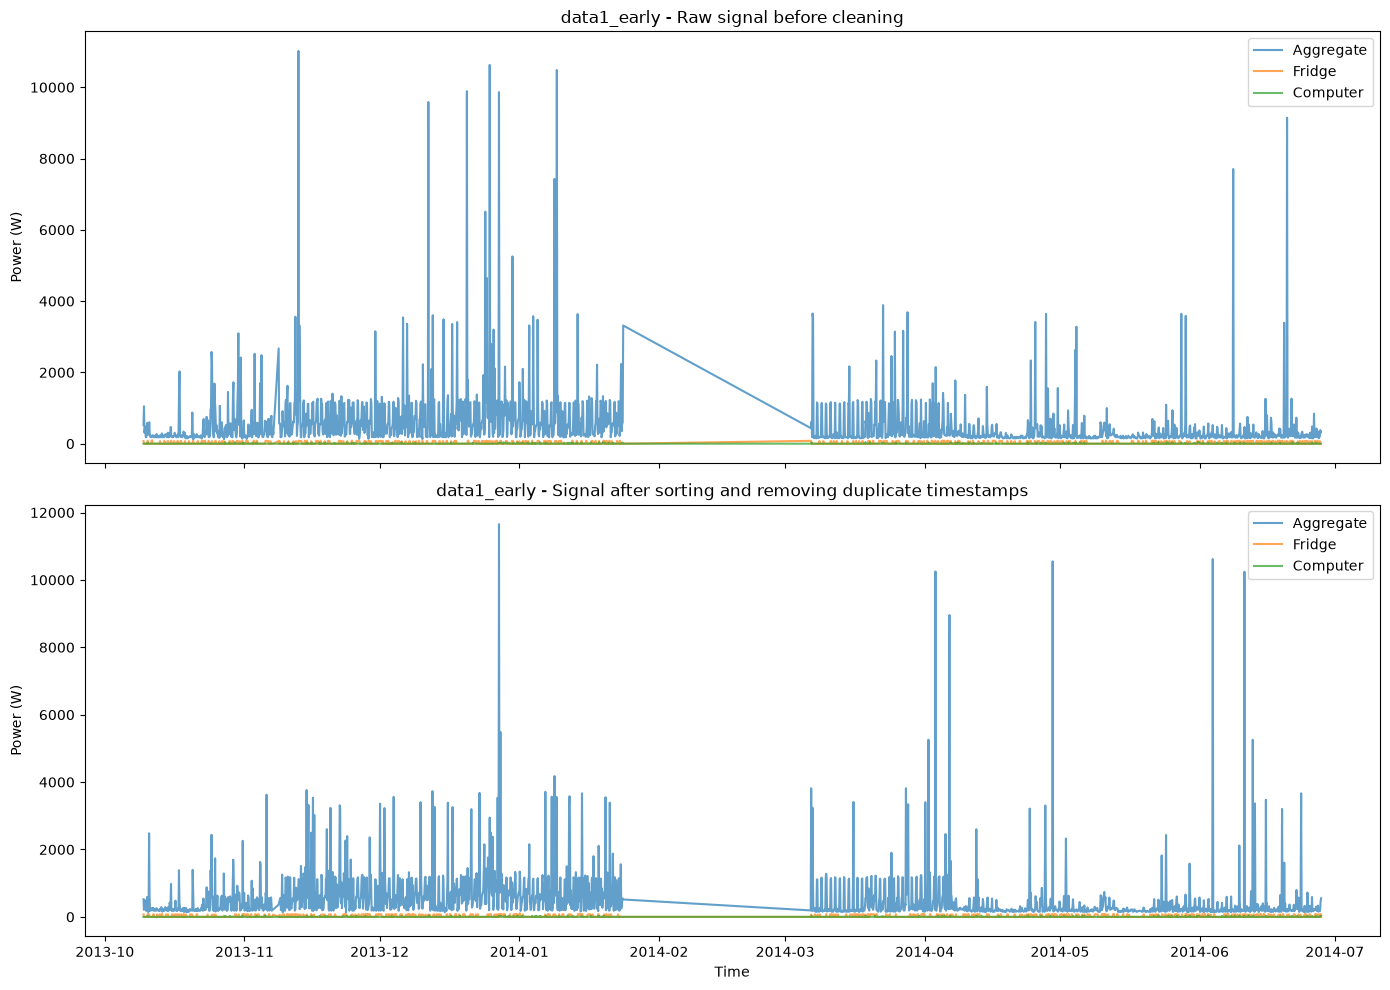

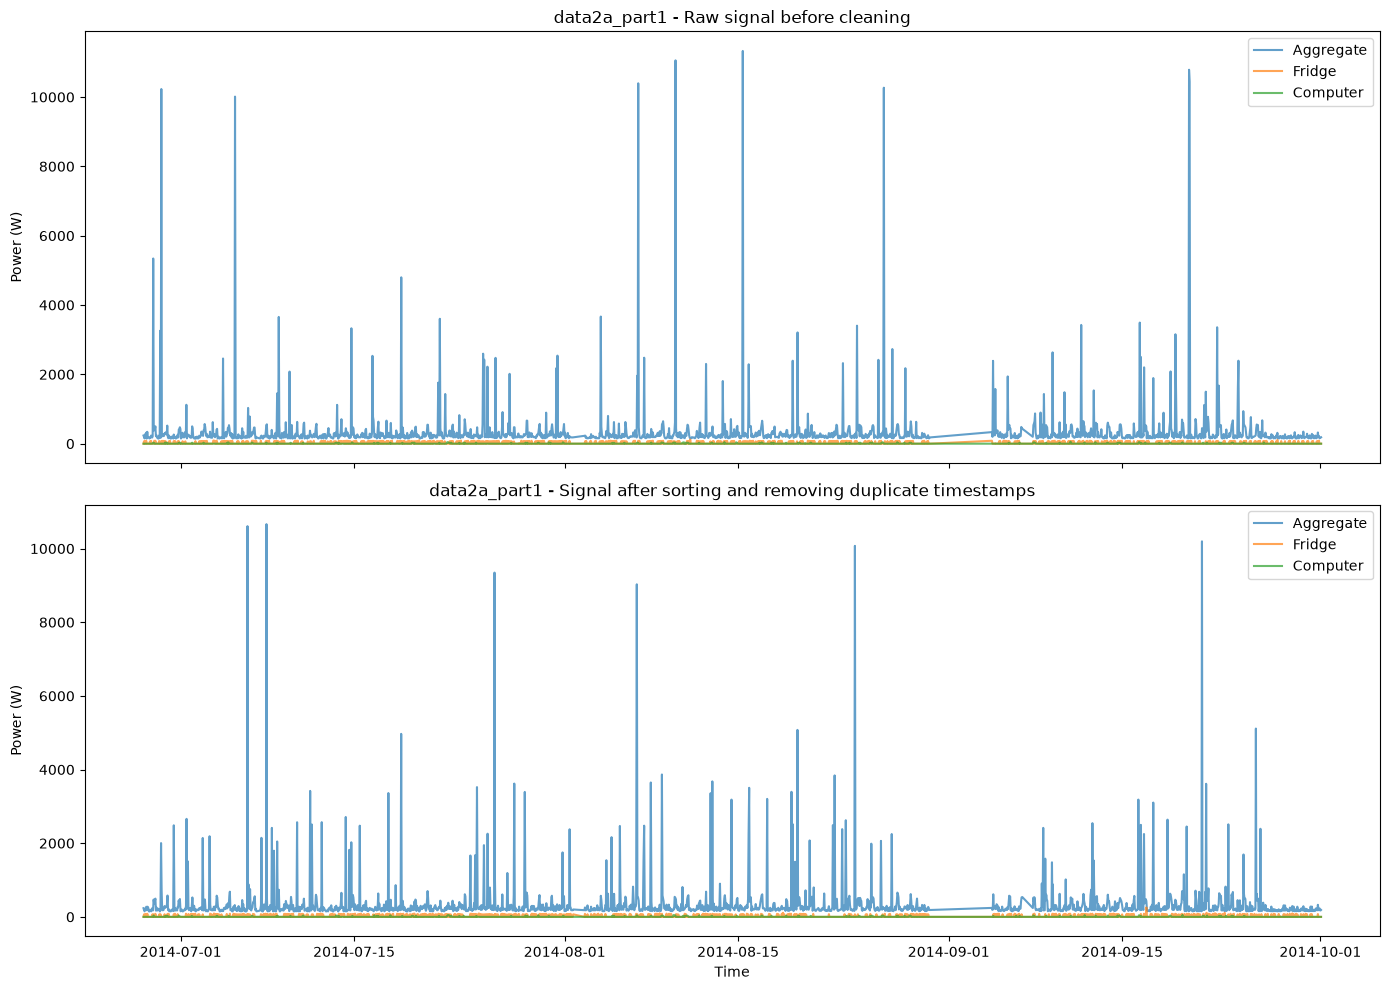

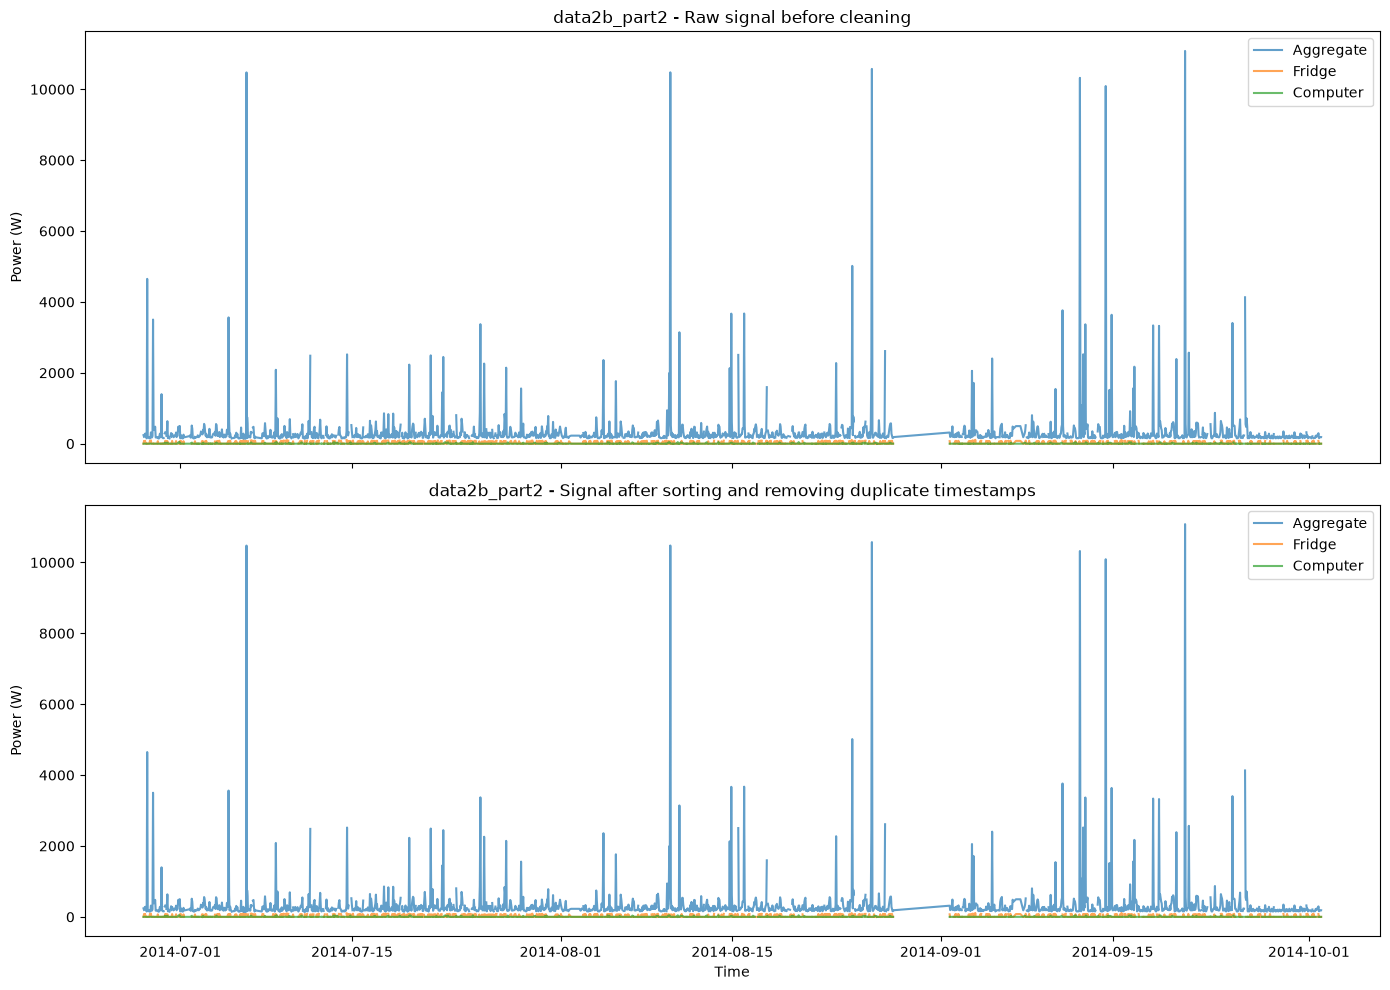

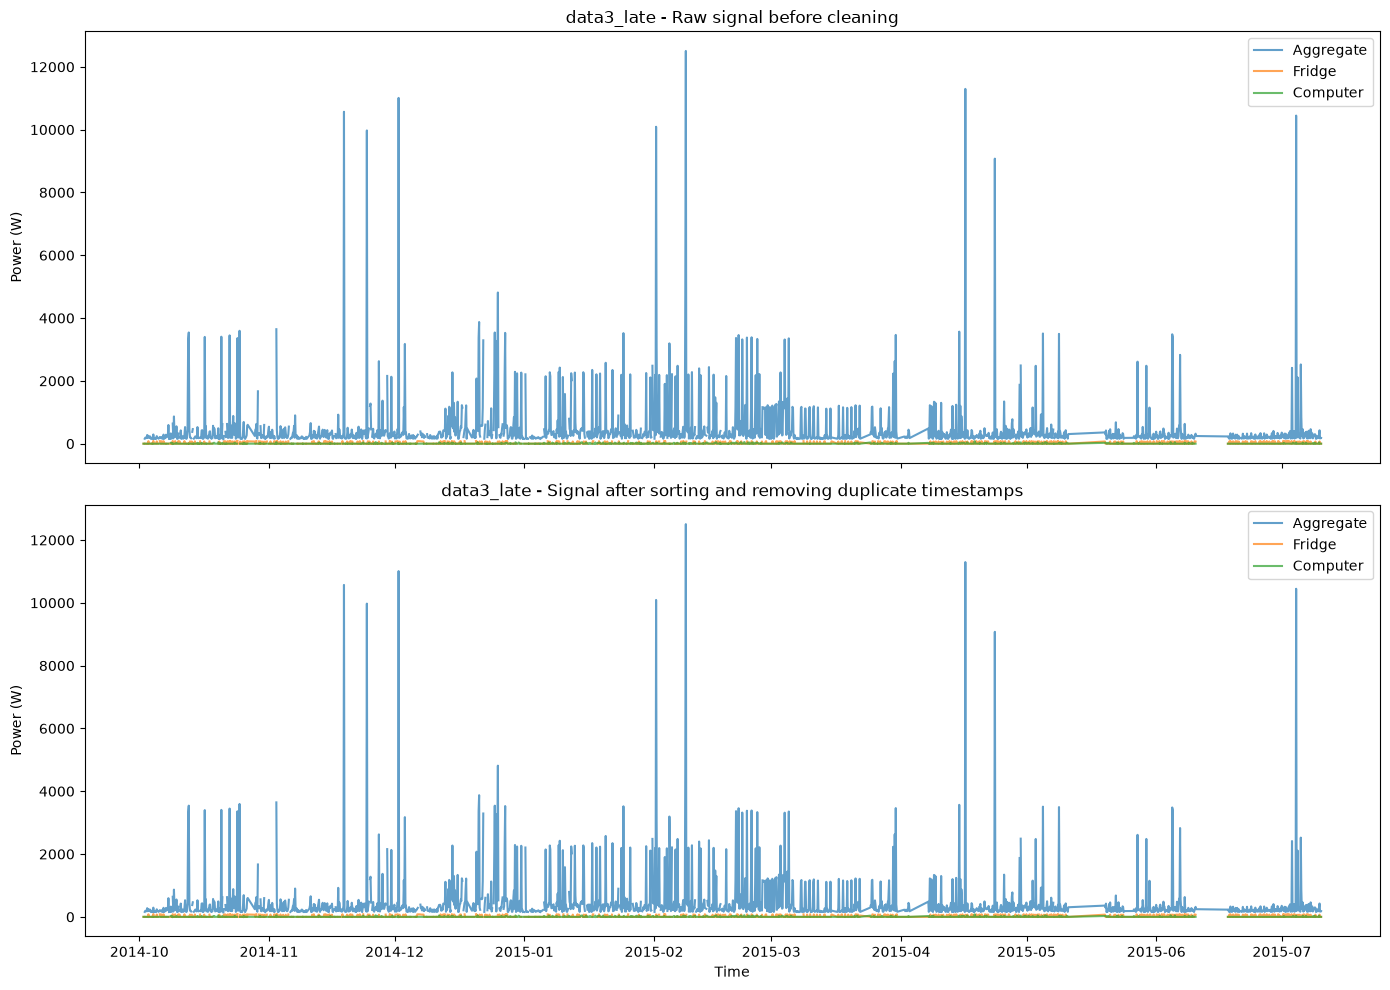

Saved before/after cleaning plots to: cleaning_results
Cleaning pipeline applied to real House 1 data copies only.


In [33]:
# Real-data pipeline for results
# This section intentionally works on copies of the raw data and saves plots.

from pathlib import Path
import matplotlib.pyplot as plt

# Build the dataset dictionary if it is not already available in the notebook state.
if 'datasets' not in globals():
    base = Path('REFIT_RAW_081116')
    part1 = pd.read_csv(base / 'RAW_House1_Part1.csv')
    part2 = pd.read_csv(base / 'RAW_House1_Part2.csv')

    for df in (part1, part2):
        df['Time'] = pd.to_datetime(df['Time'], errors='coerce')

    appliance_names = {
        'Aggregate': 'Aggregate',
        'Appliance1': 'Fridge',
        'Appliance2': 'Freezer 1',
        'Appliance3': 'Freezer 2',
        'Appliance4': 'Washer Dryer',
        'Appliance5': 'Washing Machine',
        'Appliance6': 'Dishwasher',
        'Appliance7': 'Computer',
        'Appliance8': 'Television',
        'Appliance9': 'Heater'
    }

    part1 = part1.rename(columns=appliance_names)
    part2 = part2.rename(columns=appliance_names)

    Data1 = part1[(part1['Time'] >= '2013-10-09 14:06:17') & (part1['Time'] <= '2014-06-27 23:59:50')].copy()
    Data2A = part1[(part1['Time'] >= '2014-06-28 00:00:04') & (part1['Time'] <= '2014-10-01 01:27:07')].copy()
    Data2B = part2[(part2['Time'] >= '2014-06-28 00:00:05') & (part2['Time'] <= '2014-10-01 23:59:59')].copy()
    Data3 = part2[(part2['Time'] >= '2014-10-02 00:00:07') & (part2['Time'] <= '2015-07-10 11:56:32')].copy()

    datasets = {
        'data1_early': Data1.copy(),
        'data2a_part1': Data2A.copy(),
        'data2b_part2': Data2B.copy(),
        'data3_late': Data3.copy(),
    }

results_dir = Path('cleaning_results')
results_dir.mkdir(exist_ok=True)

# Rebuild a clean working dictionary from the raw split datasets.
cleaned_real = {}
for name, df in datasets.items():
    cleaned_real[name] = df.copy()

# Documented cleaning rule for the working copy.
def apply_documented_cleaning(df):
    out = df.copy()
    out = out.sort_values('Time').reset_index(drop=True)
    out = out.drop_duplicates(subset='Time', keep='first').reset_index(drop=True)
    return out

# Apply the rule to each dataset and keep the original raw data untouched.
for name, df in list(cleaned_real.items()):
    cleaned_real[name] = apply_documented_cleaning(df)

# Plot raw vs cleaned data using a small subset for readability.
plot_cols = ['Aggregate', 'Fridge', 'Computer']

for name, raw_df in datasets.items():
    clean_df = cleaned_real[name]

    raw_plot = raw_df.sort_values('Time').copy()
    clean_plot = clean_df.sort_values('Time').copy()

    raw_plot = raw_plot.iloc[::max(1, len(raw_plot) // 2000)]
    clean_plot = clean_plot.iloc[::max(1, len(clean_plot) // 2000)]

    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

    for c in plot_cols:
        if c in raw_plot.columns:
            axes[0].plot(raw_plot['Time'], pd.to_numeric(raw_plot[c], errors='coerce'), label=c, alpha=0.7)
    axes[0].set_title(f'{name} - Raw signal before cleaning')
    axes[0].legend(loc='upper right')
    axes[0].set_ylabel('Power (W)')

    for c in plot_cols:
        if c in clean_plot.columns:
            axes[1].plot(clean_plot['Time'], pd.to_numeric(clean_plot[c], errors='coerce'), label=c, alpha=0.7)
    axes[1].set_title(f'{name} - Signal after sorting and removing duplicate timestamps')
    axes[1].legend(loc='upper right')
    axes[1].set_ylabel('Power (W)')
    axes[1].set_xlabel('Time')

    fig.tight_layout()
    fig.savefig(results_dir / f'{name}_cleaning_before_after.png', dpi=180)
    plt.show()

print('Saved before/after cleaning plots to:', results_dir)
print('Cleaning pipeline applied to real House 1 data copies only.')
